**AIVLE School 미니프로젝트**
### **공공데이터를 활용한 <span style="color:darkgreen">미세먼지 농도</span> 예측**
---

#### **<span style="color:red">[미션 안내]</span>**
* 개인 미션: 미세먼지 농도를 예측하는 머신러닝 모델을 만드세요. ([2-1]부터 [2-10], [3-1]부터 [3-2] 까지 미션 수행)
* 조별 미션: 개인 미션 수행한 내용에 대해 토론하여 발표 준비를 해주세요.

#### **<span style="color:red">[주피터 노트북 파일 안내]</span>**
1. 탐색적 데이터 분석(solution).ipynb: 미션 수행 대상 아님. 제공된 solution을 참고하여 [2-1]부터의 미션 수행을 위한 탐색적 데이터 분석 진행</br>
2. 데이터 전처리.ipynb: [2-1]부터 [2-8] 까지 미션 수행 대상</br>
3. 모델링(머신러닝).ipynb: [3-1]부터 [3-2] 까지 미션 수행 대상. [4-1]~[4-4]는 선택 사항임</br>

#### **<span style="color:red">[데이터 설명]</span>**

* air_2021.csv : 2021년 미세먼지 데이터
* air_2022.csv : 2022년 미세먼지 데이터
* weather_2021.csv : 2021년 날씨 데이터
* weather_2022.csv : 2022년 날씨 데이터
* 학습 데이터: 2021년의 미세먼지 농도 데이터, 테스트 데이터: 2022년의 미세먼지 농도 데이터

# [Step 1] 탐색적 데이터 분석

#### **<span style="color:blue">[1-1] 필요한 라이브러리 설치</span>**

In [2]:
# 필요한 라이브러리 설치 및 임포트

import pandas as pd
import seaborn as sns
import matplotlib as plt

---

#### **<span style="color:blue">[1-2] 미세먼지 데이터 불러오기</span>**

* Pandas 라이브러리를 활용해서 'air_2021.csv'파일을 'air_21' 변수에, 'air_2022.csv'파일을 'air_22' 변수에 저장하고 그 데이터를 확인하세요.
* 구분자(sep) : ','
* encoder = 'utf-8'
* index_col = 0

In [3]:
# 아래에 실습코드를 작성하고 결과를 확인합니다.
# 'air_2021.csv'파일을 'air_21' 변수에, 'air_2022.csv'파일을 'air_22' 변수에 저장
air_21 = pd.read_csv('air_2021.csv', encoding='utf-8', index_col = 0)
air_22 = pd.read_csv('air_2022.csv', encoding='utf-8', index_col = 0)

In [4]:
# air_21 데이터의 head 확인
air_21.head()


,지역,망,측정소코드,측정소명,측정일시,SO2,CO,O3,NO2,PM10,PM25,주소
0,서울 종로구,도시대기,111123,종로구,2021100101,0.003,0.6,0.002,0.039,31.0,18.0,서울 종로구 종로35가길 19
1,서울 종로구,도시대기,111123,종로구,2021100102,0.003,0.6,0.002,0.035,27.0,16.0,서울 종로구 종로35가길 19
2,서울 종로구,도시대기,111123,종로구,2021100103,0.003,0.6,0.002,0.033,28.0,18.0,서울 종로구 종로35가길 19
3,서울 종로구,도시대기,111123,종로구,2021100104,0.003,0.6,0.002,0.030,26.0,16.0,서울 종로구 종로35가길 19
4,서울 종로구,도시대기,111123,종로구,2021100105,0.003,0.5,0.003,0.026,26.0,16.0,서울 종로구 종로35가길 19


In [5]:
# air_21 데이터의 shape 확인
air_21.shape

(8760, 12)

In [6]:
# air_22 데이터의 head 확인
air_22.head()


,지역,망,측정소코드,측정소명,측정일시,SO2,CO,O3,NO2,PM10,PM25,주소
0,서울 종로구,도시대기,111123,종로구,2022010101,0.003,0.4,0.026,0.016,23.0,12.0,서울 종로구 종로35가길 19
1,서울 종로구,도시대기,111123,종로구,2022010102,0.003,0.4,0.022,0.020,20.0,9.0,서울 종로구 종로35가길 19
2,서울 종로구,도시대기,111123,종로구,2022010103,0.003,0.5,0.014,0.028,20.0,9.0,서울 종로구 종로35가길 19
3,서울 종로구,도시대기,111123,종로구,2022010104,0.003,0.5,0.016,0.027,19.0,10.0,서울 종로구 종로35가길 19
4,서울 종로구,도시대기,111123,종로구,2022010105,0.003,0.5,0.005,0.040,24.0,11.0,서울 종로구 종로35가길 19


In [7]:
# air_22 데이터의 shape 확인

air_22.shape

(2160, 12)

---

#### **<span style="color:blue">[1-3] 날씨 데이터 불러오기</span>**

* Pandas 라이브러리를 활용해서 'weather_2021.csv'파일을 'weather_21' 변수에, 'weather_2022.csv'파일을 'weather_22' 변수에 저장하고 그 데이터를 확인하세요.
* 구분자(sep) : ','
* encoder = 'cp949'

In [8]:
#'weather_2021.csv'파일을 'weather_21' 변수에, 'weather_2022.csv'파일을 'weather_22' 변수에 저장
weather_21 = pd.read_csv('weather_2021.csv', encoding='cp949')
weather_22 = pd.read_csv('weather_2022.csv', encoding='cp949')


In [9]:
# 미세먼지 데이터와 같이 날씨 데이터의 head, shape 등을 확인
print(weather_21.head())

    지점 지점명                일시  기온(°C)  기온 QC플래그  강수량(mm)  강수량 QC플래그  풍속(m/s)  \
0  108  서울  2021-01-01 01:00    -8.7       NaN      NaN        NaN      2.4   
1  108  서울  2021-01-01 02:00    -9.1       NaN      NaN        NaN      1.6   
2  108  서울  2021-01-01 03:00    -9.3       NaN      NaN        NaN      1.1   
3  108  서울  2021-01-01 04:00    -9.3       NaN      NaN        NaN      0.3   
4  108  서울  2021-01-01 05:00    -9.7       NaN      NaN        NaN      1.9   

   풍속 QC플래그  풍향(16방위)  ...  최저운고(100m )  시정(10m)  지면상태(지면상태코드)  현상번호(국내식)  \
0       NaN     270.0  ...          NaN     2000           NaN        NaN   
1       NaN     270.0  ...          NaN     2000           NaN        NaN   
2       NaN     250.0  ...          NaN     2000           NaN        NaN   
3       NaN       0.0  ...          NaN     2000           NaN        NaN   
4       NaN      20.0  ...          NaN     2000           NaN        NaN   

   지면온도(°C)  지면온도 QC플래그  5cm 지중온도(°C)  10cm 지중온도(°C)  20cm 지중온

In [10]:
print(weather_22.head())

    지점 지점명                일시  기온(°C)  기온 QC플래그  강수량(mm)  강수량 QC플래그  풍속(m/s)  \
0  108  서울  2022-01-01 00:00    -8.5       NaN      NaN        NaN      1.9   
1  108  서울  2022-01-01 01:00    -9.2       NaN      NaN        NaN      1.8   
2  108  서울  2022-01-01 02:00    -9.5       NaN      NaN        NaN      1.2   
3  108  서울  2022-01-01 03:00    -9.3       NaN      NaN        NaN      1.4   
4  108  서울  2022-01-01 04:00    -9.6       NaN      NaN        NaN      1.7   

   풍속 QC플래그  풍향(16방위)  ...  최저운고(100m )  시정(10m)  지면상태(지면상태코드)  현상번호(국내식)  \
0       NaN       320  ...          NaN     2000           NaN        NaN   
1       NaN       270  ...          NaN     2000           NaN        NaN   
2       NaN       270  ...          NaN     2000           NaN        NaN   
3       NaN       290  ...          NaN     2000           NaN        NaN   
4       NaN       340  ...          NaN     2000           NaN        NaN   

   지면온도(°C)  지면온도 QC플래그  5cm 지중온도(°C)  10cm 지중온도(°C)  20cm 지중온

In [11]:
print(weather_21.shape)
print(weather_22.shape)


(8759, 38)
(2160, 38)


---

#### **<span style="color:blue">[1-4] 데이터 변수 확인</span>**

In [12]:
# 각 데이터프레임의 info 확인
air_21.info()


<class 'pandas.core.frame.DataFrame'>
Index: 8760 entries, 0 to 8759
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   지역      8760 non-null   object 
 1   망       8760 non-null   object 
 2   측정소코드   8760 non-null   int64  
 3   측정소명    8760 non-null   object 
 4   측정일시    8760 non-null   int64  
 5   SO2     8648 non-null   float64
 6   CO      8680 non-null   float64
 7   O3      8663 non-null   float64
 8   NO2     8680 non-null   float64
 9   PM10    8655 non-null   float64
 10  PM25    8663 non-null   float64
 11  주소      8760 non-null   object 
dtypes: float64(6), int64(2), object(4)
memory usage: 889.7+ KB


In [13]:
air_22.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2160 entries, 0 to 2159
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   지역      2160 non-null   object 
 1   망       2160 non-null   object 
 2   측정소코드   2160 non-null   int64  
 3   측정소명    2160 non-null   object 
 4   측정일시    2160 non-null   int64  
 5   SO2     2139 non-null   float64
 6   CO      2139 non-null   float64
 7   O3      2139 non-null   float64
 8   NO2     2139 non-null   float64
 9   PM10    2122 non-null   float64
 10  PM25    2135 non-null   float64
 11  주소      2160 non-null   object 
dtypes: float64(6), int64(2), object(4)
memory usage: 219.4+ KB


In [14]:
# 아래에 필요한 코드를 작성하고 결과를 확인합니다.
weather_21.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8759 entries, 0 to 8758
Data columns (total 38 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   지점             8759 non-null   int64  
 1   지점명            8759 non-null   object 
 2   일시             8759 non-null   object 
 3   기온(°C)         8759 non-null   float64
 4   기온 QC플래그       0 non-null      float64
 5   강수량(mm)        949 non-null    float64
 6   강수량 QC플래그      1763 non-null   float64
 7   풍속(m/s)        8757 non-null   float64
 8   풍속 QC플래그       2 non-null      float64
 9   풍향(16방위)       8757 non-null   float64
 10  풍향 QC플래그       2 non-null      float64
 11  습도(%)          8759 non-null   int64  
 12  습도 QC플래그       0 non-null      float64
 13  증기압(hPa)       8759 non-null   float64
 14  이슬점온도(°C)      8759 non-null   float64
 15  현지기압(hPa)      8759 non-null   float64
 16  현지기압 QC플래그     0 non-null      float64
 17  해면기압(hPa)      8759 non-null   float64
 18  해면기압 QC플

In [15]:
# 아래에 필요한 코드를 작성하고 결과를 확인합니다.
weather_22.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 38 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   지점             2160 non-null   int64  
 1   지점명            2160 non-null   object 
 2   일시             2160 non-null   object 
 3   기온(°C)         2160 non-null   float64
 4   기온 QC플래그       0 non-null      float64
 5   강수량(mm)        81 non-null     float64
 6   강수량 QC플래그      382 non-null    float64
 7   풍속(m/s)        2160 non-null   float64
 8   풍속 QC플래그       0 non-null      float64
 9   풍향(16방위)       2160 non-null   int64  
 10  풍향 QC플래그       0 non-null      float64
 11  습도(%)          2160 non-null   int64  
 12  습도 QC플래그       0 non-null      float64
 13  증기압(hPa)       2160 non-null   float64
 14  이슬점온도(°C)      2160 non-null   float64
 15  현지기압(hPa)      2160 non-null   float64
 16  현지기압 QC플래그     0 non-null      float64
 17  해면기압(hPa)      2160 non-null   float64
 18  해면기압 QC플

---

#### **<span style="color:blue">[1-5] 미세먼지 데이터 분석</span>**

* 데이터 전처리와 모델링을 위해 데이터 분석을 진행해보세요. 시각화 등을 통해 관측치들의 패턴 탐색, 잘못된 자료 탐색, 변수들간의 관계 파악을 할 수 있습니다.

In [16]:
# 시각화 한글폰트 설정 (아래 코드를 실행하세요)

plt.rc('font', family='Malgun Gothic')
sns.set(font="Malgun Gothic",#"NanumGothicCoding", 
        rc={"axes.unicode_minus":False}, # 마이너스 부호 깨짐 현상 해결
        style='darkgrid')

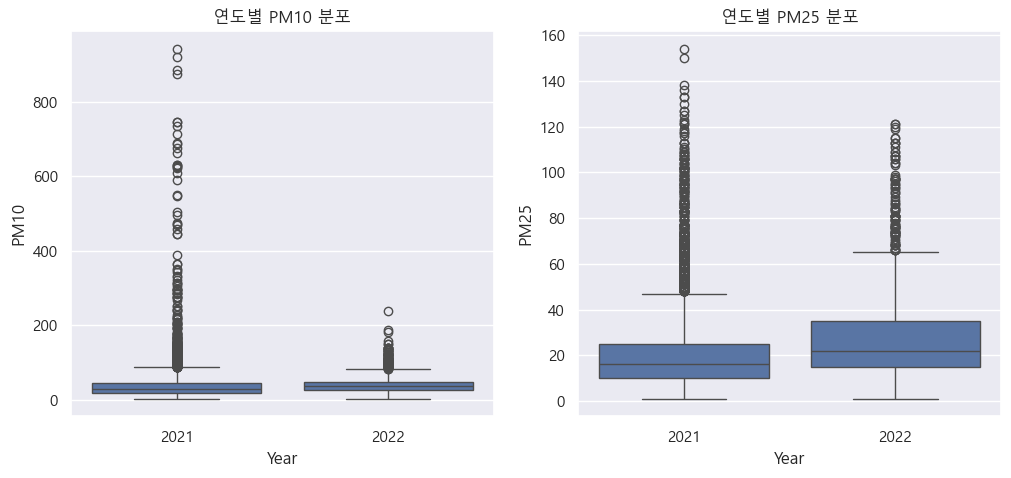

<Figure size 640x480 with 0 Axes>

In [19]:
# air_21,air_22 의 다양한 변수에 대하여 시각화
import pandas as pd
import matplotlib.pyplot as plt

# 연도 구분을 위해 Year 컬럼 추가
air_21['Year'] = '2021'
air_22['Year'] = '2022'
air_combined = pd.concat([air_21, air_22], ignore_index=True)

pollutants = ['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']

# -- 1. Boxplot (연도별 미세먼지 분포) --
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(x='Year', y='PM10', data=air_combined)
plt.title('연도별 PM10 분포')
plt.savefig('연도별 PM10 분포.png')

plt.subplot(1, 2, 2)
sns.boxplot(x='Year', y='PM25', data=air_combined)
plt.title('연도별 PM25 분포')
plt.show()
plt.savefig('연도별 PM25 분포.png')

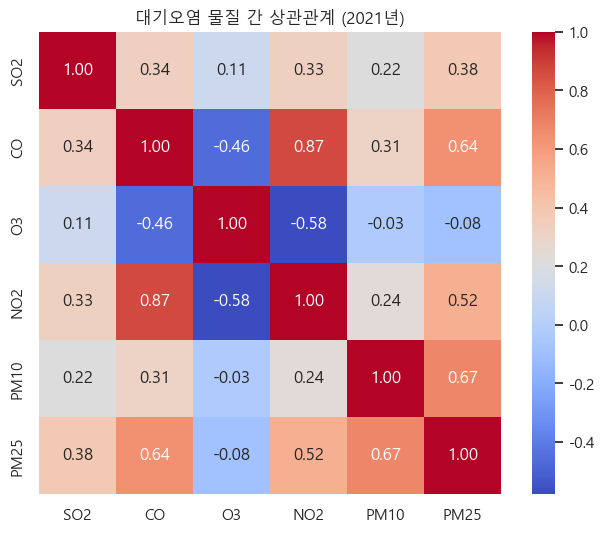

In [20]:
# 아래에 필요한 코드를 작성하고 결과를 확인합니다.

# -- 2. Heatmap (오염 물질 간 상관관계) --
plt.figure(figsize=(8, 6))
sns.heatmap(air_21[pollutants].corr(), annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title('대기오염 물질 간 상관관계 (2021년)')
plt.show()

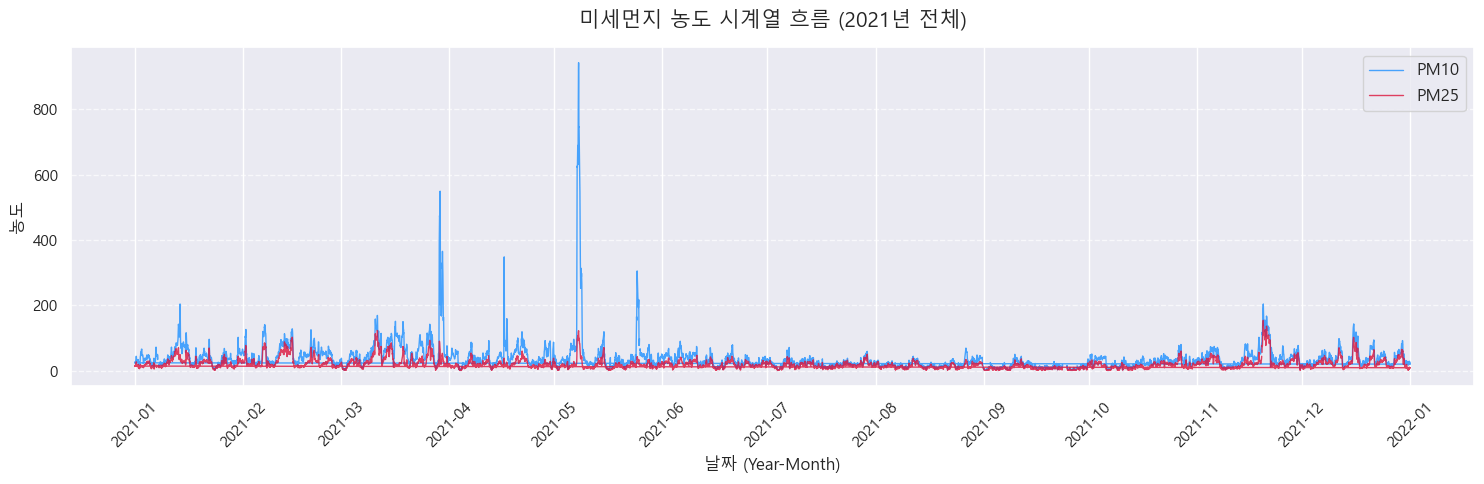

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# 1. '24시' 에러 해결 및 날짜 변환
air_21['time_str'] = air_21['측정일시'].astype(str)
air_21['time_str'] = air_21['time_str'].str[:-2] + (air_21['time_str'].str[-2:].astype(int) - 1).astype(str).str.zfill(2)
air_21['time'] = pd.to_datetime(air_21['time_str'], format='%Y%m%d%H') + pd.Timedelta(hours=1)

# 2. 1년 통짜 시계열 그래프 생성
plt.figure(figsize=(15, 5))

# 🌟 수정: [:1000] 슬라이싱을 지워서 1년 치(8760시간) 데이터를 통째로 그립니다.
plt.plot(air_21['time'], air_21['PM10'], label='PM10', color='dodgerblue', linewidth=1, alpha=0.8)
plt.plot(air_21['time'], air_21['PM25'], label='PM25', color='crimson', linewidth=1, alpha=0.8)

plt.title('미세먼지 농도 시계열 흐름 (2021년 전체)', fontsize=15, pad=15)
plt.xlabel('날짜 (Year-Month)', fontsize=12)
plt.ylabel('농도', fontsize=12)
plt.legend(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 3. x축 날짜 표기 방식 다듬기 (월 단위로 변경)
ax = plt.gca()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m')) # 연-월 형태로 표시 (예: 2021-03)
ax.xaxis.set_major_locator(mdates.MonthLocator())           # 매 월 1일 간격으로 표시
plt.xticks(rotation=45)
plt.savefig('misemunji.png')
plt.tight_layout()
plt.show()


In [22]:
# 시각화를 통해 알게된 사실을 정리해봅니다.
# 1. 이상치가 굉장히 압도적이다.
# 2. 이산화 질소의 존재감이 ㄷㄷ함
# 3. 굉장히 파멸적인 날씨들이 좀 있다. 예를 들어서 4-5월쯤..

---

#### **<span style="color:blue">[1-6] 날씨 데이터 분석</span>**

In [24]:
# '24시' 표기 문제 해결 및 datetime 변환 (1을 빼서 변환 후 1시간 더하기)
air_21['time_str'] = air_21['측정일시'].astype(str)
air_21['time_str'] = air_21['time_str'].str[:-2] + (air_21['time_str'].str[-2:].astype(int) - 1).astype(str).str.zfill(2)
air_21['time'] = pd.to_datetime(air_21['time_str'], format='%Y%m%d%H') + pd.Timedelta(hours=1)
air_21.drop(columns=['time_str'], inplace=True) # 임시 컬럼 삭제

# ---------------------------------------------------
# 2. 날씨(weather) 데이터 불러오기 및 시간 변환
# ---------------------------------------------------
weather_21['time'] = pd.to_datetime(weather_21['일시'])

# ---------------------------------------------------
# 3. 데이터 병합 (Merge) 및 타겟 변수(y) 생성
# ---------------------------------------------------
# 공통 컬럼인 'time'을 기준으로 병합
df_21 = pd.merge(air_21, weather_21, on='time', how='inner')

# 머신러닝이 맞출 정답(y): '1시간 후의 PM10 농도'
# shift(-1)을 사용해 다음 행(1시간 뒤)의 PM10 값을 현재 행으로 당겨옵니다.
df_21['y'] = df_21['PM10'].shift(-1)

# 마지막 행은 '1시간 뒤'의 데이터가 없으므로 결측치(NaN)가 됩니다. 이를 제거합니다.
df_21.dropna(subset=['y'], inplace=True)

# ---------------------------------------------------
# 4. 결과 확인
# ---------------------------------------------------
print("✅ 데이터 병합 완료! 총 행 개수:", df_21.shape[0])
display(df_21[['time', 'PM10', 'y']].head())

✅ 데이터 병합 완료! 총 행 개수: 8653


,time,PM10,y
0,2021-10-01 01:00:00,31.0,27.0
1,2021-10-01 02:00:00,27.0,28.0
2,2021-10-01 03:00:00,28.0,26.0
3,2021-10-01 04:00:00,26.0,26.0
4,2021-10-01 05:00:00,26.0,22.0


C:\Users\5174k\AppData\Local\Temp\ipykernel_16372\492404168.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Year', y=col, data=w_combined, palette='Set2')
C:\Users\5174k\AppData\Local\Temp\ipykernel_16372\492404168.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Year', y=col, data=w_combined, palette='Set2')
C:\Users\5174k\AppData\Local\Temp\ipykernel_16372\492404168.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Year', y=col, data=w_combined, palette='Set2')


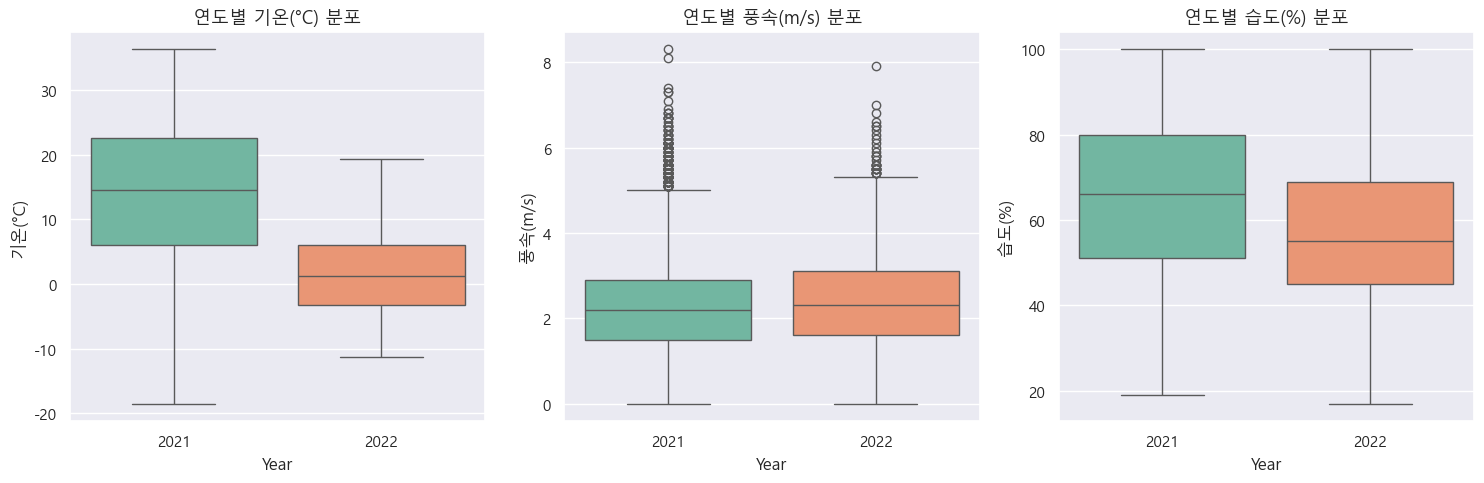

In [25]:
# weather_21,weather_22 의 다양한 변수에 대하여 시각화

# 연도 구분을 위해 Year 컬럼 추가 및 병합
weather_21['Year'] = '2021'
weather_22['Year'] = '2022'
weather_21['time'] = pd.to_datetime(weather_21['일시'])
weather_22['time'] = pd.to_datetime(weather_22['일시'])

w_combined = pd.concat([weather_21, weather_22], ignore_index=True)

# 주요 날씨 변수 4가지 선정
cols = ['기온(°C)', '풍속(m/s)', '습도(%)', '현지기압(hPa)']

# ---------------------------------------------------
# 🎨 1. Boxplot (연도별 날씨 분포)
# ---------------------------------------------------
plt.figure(figsize=(15, 5))
for i, col in enumerate(['기온(°C)', '풍속(m/s)', '습도(%)']):
    plt.subplot(1, 3, i+1)
    sns.boxplot(x='Year', y=col, data=w_combined, palette='Set2')
    plt.title(f'연도별 {col} 분포', fontsize=13)
plt.tight_layout()
plt.show()


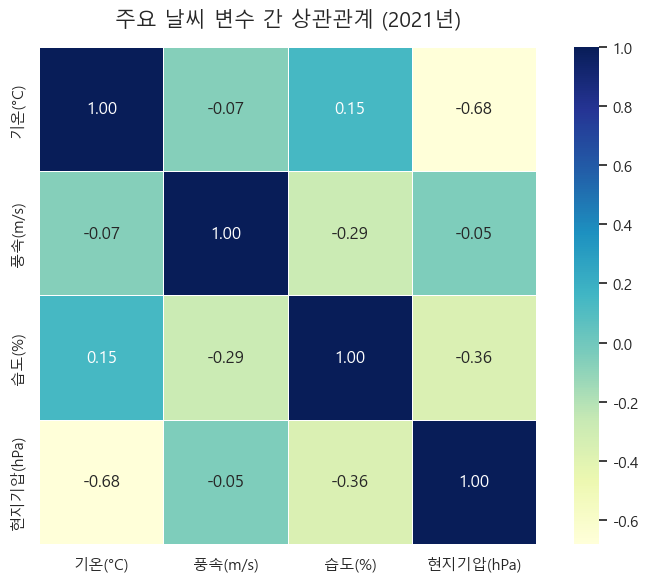

In [26]:
# 아래에 필요한 코드를 작성하고 결과를 확인합니다.


# ---------------------------------------------------
# 🎨 2. Heatmap (날씨 변수 상관관계)
# ---------------------------------------------------
plt.figure(figsize=(8, 6))
sns.heatmap(weather_21[cols].corr(), annot=True, cmap='YlGnBu', fmt='.2f', square=True,
            linewidths=.5, annot_kws={'size': 12})
plt.title('주요 날씨 변수 간 상관관계 (2021년)', fontsize=15, pad=15)
plt.tight_layout()
plt.show()



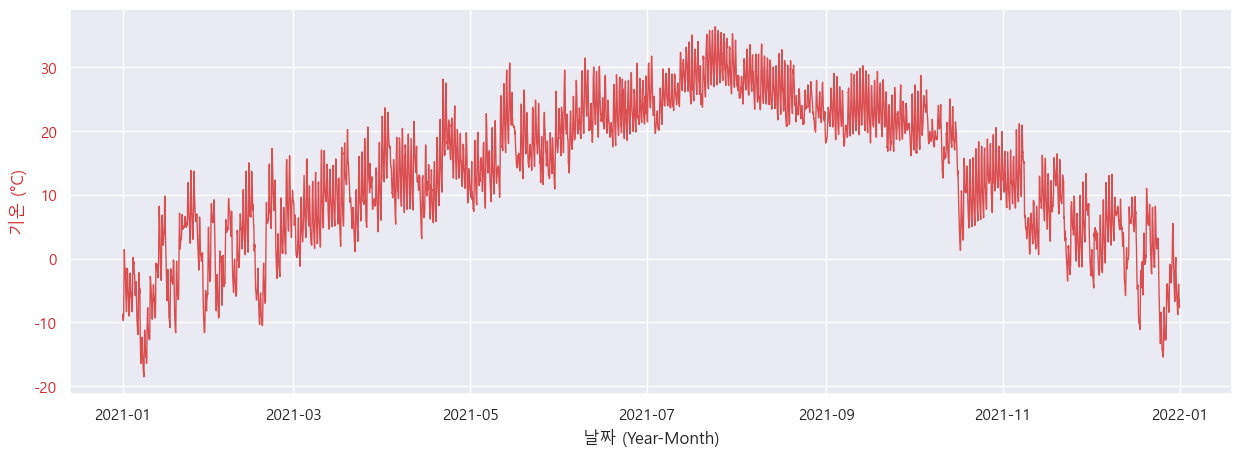

In [27]:
# 아래에 필요한 코드를 작성하고 결과를 확인합니다.

# ---------------------------------------------------
# 🎨 3. Time Series (기온 & 습도 1년 흐름 - 이중 y축)
# ---------------------------------------------------
fig, ax1 = plt.subplots(figsize=(15, 5))

# 기온 플롯 (왼쪽 y축, 빨간색)
color = 'tab:red'
ax1.set_xlabel('날짜 (Year-Month)', fontsize=12)
ax1.set_ylabel('기온 (°C)', color=color, fontsize=12)
ax1.plot(weather_21['time'], weather_21['기온(°C)'], color=color, alpha=0.8, linewidth=1)
ax1.tick_params(axis='y', labelcolor=color)






In [28]:
# 시각화를 통해 알게된 사실을 정리해봅니다.
# 1.  21년 1월이 진짜 추웠구나
# 2.  21년 8월이 진짜 더웠구나
# 3.  생각보다는? 기온이 습도에 미치는 영향이 적다